# =============================================================================
# Author: G.A.N.M.Perera
# Student ID: 20240694
# Peer Reviewer: [Enter Peer Name Here]
# Review Date: 15/04/2026
# Module: 5DATA002W.2 — Machine Learning & Data Mining
# Task: Notebook 1
# =============================================================================

In [4]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/loan_approval_data.csv')


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/loan_approval_data.csv'

In [ ]:
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (58645, 13)


,id,age,income,home_ownership,emplyment_length,loan_intent,loan_amount,loan_interest_rate,loan_income_ratio,payment_default_on_file,credit_history_length,loan_approval_status,max_allowed_loan
0,35437,21.0,12000,OWN,0,EDUCATION,15000,6.99,0.12,N,4,0,-2426900
1,53756,21.0,13200,OWN,2,EDUCATION,25000,16.77,0.19,Y,3,0,-111739
2,42205,23.0,9600,RENT,5,MEDICAL,30000,12.42,0.31,N,3,0,-89000
3,19180,40.0,182004,RENT,3,EDUCATION,35000,8.00,0.19,N,11,0,35000
4,28072,40.0,90000,MORTGAGE,3,HOMEIMPROVEMENT,35000,12.42,0.39,N,14,0,35000


In [ ]:
# Column names
print("Columns:")
print(list(df.columns))

# Data types + non-null counts
df.info()

# Basic stats for numeric
df.describe()

Columns:
['id', 'age', 'income', 'home_ownership', 'emplyment_length', 'loan_intent', 'loan_amount', 'loan_interest_rate', 'loan_income_ratio', 'payment_default_on_file', 'credit_history_length', 'loan_approval_status', 'max_allowed_loan']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       58645 non-null  int64  
 1   age                      58639 non-null  float64
 2   income                   58645 non-null  int64  
 3   home_ownership           58645 non-null  object 
 4   emplyment_length         58645 non-null  int64  
 5   loan_intent              58645 non-null  object 
 6   loan_amount              58645 non-null  int64  
 7   loan_interest_rate       58634 non-null  float64
 8   loan_income_ratio        58645 non-null  float64
 9   payment_default_on_file  58640 non-null  object 
 10

,id,age,income,emplyment_length,loan_amount,loan_interest_rate,loan_income_ratio,credit_history_length,loan_approval_status,max_allowed_loan
count,58645.000000,58639.000000,5.864500e+04,58645.000000,58645.000000,58634.000000,58645.000000,58645.000000,58645.000000,5.864500e+04
mean,29322.000000,27.550913,6.404617e+04,4.703487,9217.556518,10.677526,0.159238,5.813556,0.142382,6.975472e+04
std,16929.497605,6.033217,3.793111e+04,4.004982,5563.807384,3.036034,0.091692,4.029196,0.349445,6.175091e+04
min,0.000000,20.000000,4.200000e+03,0.000000,500.000000,-11.140000,0.000000,2.000000,0.000000,-2.426900e+06
25%,14661.000000,23.000000,4.200000e+04,2.000000,5000.000000,7.880000,0.090000,3.000000,0.000000,3.800300e+04
50%,29322.000000,26.000000,5.800000e+04,4.000000,8000.000000,10.750000,0.140000,4.000000,0.000000,6.239200e+04
75%,43983.000000,30.000000,7.560000e+04,7.000000,12000.000000,12.990000,0.210000,8.000000,0.000000,9.271600e+04
max,58644.000000,123.000000,1.900000e+06,150.000000,35000.000000,23.220000,0.830000,30.000000,1.000000,2.638778e+06


In [ ]:
# Missing values counts
print("Missing values per column:")
print(df.isnull().sum())

# Missing values percentage
print("\nMissing values % per column:")
print((df.isna().sum() / len(df) * 100).round(2))

Missing values per column:
id                          0
age                         6
income                      0
home_ownership              0
emplyment_length            0
loan_intent                 0
loan_amount                 0
loan_interest_rate         11
loan_income_ratio           0
payment_default_on_file     5
credit_history_length       0
loan_approval_status        0
max_allowed_loan            0
dtype: int64

Missing values % per column:
id                         0.00
age                        0.01
income                     0.00
home_ownership             0.00
emplyment_length           0.00
loan_intent                0.00
loan_amount                0.00
loan_interest_rate         0.02
loan_income_ratio          0.00
payment_default_on_file    0.01
credit_history_length      0.00
loan_approval_status       0.00
max_allowed_loan           0.00
dtype: float64


In [ ]:
loan_approval_status = "Loan Approval Status"   # classification y
max_allowed_loan  = "Maximum Loan Amount"    # regression y

print("Classification target:", loan_approval_status)
print("Regression target:", max_allowed_loan)

Classification target: Loan Approval Status
Regression target: Maximum Loan Amount


loan_approval_status
0    50295
1     8350
Name: count, dtype: int64


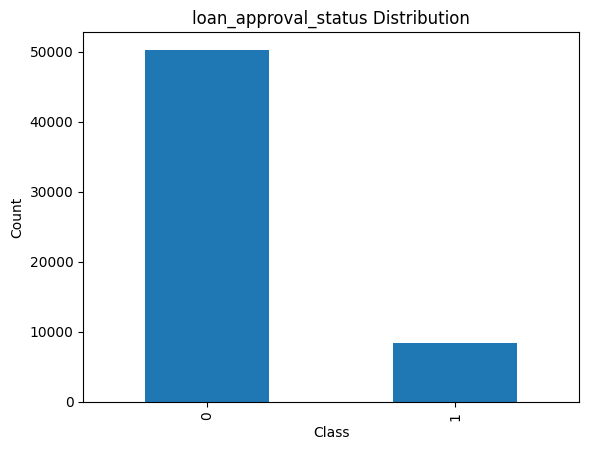

In [ ]:
import matplotlib.pyplot as plt

print(df["loan_approval_status"].value_counts(dropna=False))

df["loan_approval_status"].value_counts(dropna=False).plot(kind="bar")
plt.title("loan_approval_status Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()


In [ ]:
# Making a copy to keep raw df untouched
df_clean = df.copy()

drop_cols = ["ID", "CustomerID", "Name", "id", "customer_id", "name"]
drop_cols = [c for c in drop_cols if c in df_clean.columns]


df_clean = df_clean.drop(columns=drop_cols)

print("Dropped columns:", drop_cols)
print("New shape:", df_clean.shape)
df_clean.head()


Dropped columns: ['id']
New shape: (58645, 12)


,age,income,home_ownership,emplyment_length,loan_intent,loan_amount,loan_interest_rate,loan_income_ratio,payment_default_on_file,credit_history_length,loan_approval_status,max_allowed_loan
0,21.0,12000,OWN,0,EDUCATION,15000,6.99,0.12,N,4,0,-2426900
1,21.0,13200,OWN,2,EDUCATION,25000,16.77,0.19,Y,3,0,-111739
2,23.0,9600,RENT,5,MEDICAL,30000,12.42,0.31,N,3,0,-89000
3,40.0,182004,RENT,3,EDUCATION,35000,8.00,0.19,N,11,0,35000
4,40.0,90000,MORTGAGE,3,HOMEIMPROVEMENT,35000,12.42,0.39,N,14,0,35000


In [ ]:
import numpy as np

# Separate numeric and object columns
num_cols = df_clean.select_dtypes(include=[np.number]).columns
cat_cols = df_clean.select_dtypes(include=["object"]).columns

# Mean imputation for numeric columns
for col in num_cols:
    mean_val = df_clean[col].mean()
    df_clean[col] = df_clean[col].fillna(mean_val)

# Mode imputation for categorical columns
for col in cat_cols:
    if df_clean[col].isna().sum() > 0:
        mode_val = df_clean[col].mode(dropna=True)[0]
        df_clean[col] = df_clean[col].fillna(mode_val)

# Check missing again
print("Missing after imputation (top 20):")
print(df_clean.isnull().sum().sort_values(ascending=False).head(20))


Missing after imputation (top 20):
age                        0
income                     0
home_ownership             0
emplyment_length           0
loan_intent                0
loan_amount                0
loan_interest_rate         0
loan_income_ratio          0
payment_default_on_file    0
credit_history_length      0
loan_approval_status       0
max_allowed_loan           0
dtype: int64


In [ ]:
from sklearn import preprocessing

df_encoded = df_clean.copy()

label_encoder = preprocessing.LabelEncoder()

# Encode only object columns
for col in df_encoded.select_dtypes(include=["object"]).columns:
    df_encoded[col] = label_encoder.fit_transform(df_encoded[col].astype(str))

df_encoded.head()


,age,income,home_ownership,emplyment_length,loan_intent,loan_amount,loan_interest_rate,loan_income_ratio,payment_default_on_file,credit_history_length,loan_approval_status,max_allowed_loan
0,21.0,12000,2,0,1,15000,6.99,0.12,0,4,0,-2426900
1,21.0,13200,2,2,1,25000,16.77,0.19,1,3,0,-111739
2,23.0,9600,3,5,3,30000,12.42,0.31,0,3,0,-89000
3,40.0,182004,3,3,1,35000,8.00,0.19,0,11,0,35000
4,40.0,90000,0,3,2,35000,12.42,0.39,0,14,0,35000


In [ ]:
# Drop rows where classification target is missing
df_class = df_encoded.dropna(subset=["loan_approval_status"]).copy()

# Separate target
y_class = df_class["loan_approval_status"].copy()

# Features = everything except classification target
X_class = df_class.drop(columns=["loan_approval_status"], errors="ignore").copy()

# Remove regression target from classification features to avoid leakage
X_class = X_class.drop(columns=["max_allowed_loan"], errors="ignore")

print("X_class shape:", X_class.shape)
print("y_class shape:", y_class.shape)

print("\nClass distribution:")
print(y_class.value_counts(dropna=False))


X_class shape: (58645, 10)
y_class shape: (58645,)

Class distribution:
loan_approval_status
0    50295
1     8350
Name: count, dtype: int64


In [ ]:
# Approved label for 0/1 target
APPROVED_LABEL = 1

# Keep only approved rows
df_reg = df_encoded[df_encoded["loan_approval_status"] == APPROVED_LABEL].copy()

# Drop rows where regression target is missing
df_reg = df_reg.dropna(subset=["max_allowed_loan"]).copy()

# Convert regression target to numeric safely
df_reg["max_allowed_loan"] = pd.to_numeric(df_reg["max_allowed_loan"], errors="coerce")

# Drop rows where conversion failed
df_reg = df_reg.dropna(subset=["max_allowed_loan"]).copy()

# Target
y_reg = df_reg["max_allowed_loan"].copy()

# Features
X_reg = df_reg.drop(columns=["loan_approval_status", "max_allowed_loan"], errors="ignore").copy()

print("X_reg shape:", X_reg.shape)
print("y_reg shape:", y_reg.shape)
print("\nRegression target stats:\n", y_reg.describe())



X_reg shape: (8350, 10)
y_reg shape: (8350,)

Regression target stats:
 count    8350.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: max_allowed_loan, dtype: float64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_class_scaled = scaler.fit_transform(X_class)

print("X_class_scaled shape:", X_class_scaled.shape)


X_class_scaled shape: (58645, 10)


In [ ]:
# Save classification dataset
X_class.to_csv("/content/X_class_prepared.csv", index=False)
y_class.to_csv("/content/y_class.csv", index=False)

# Save regression dataset
X_reg.to_csv("/content/X_reg_prepared.csv", index=False)
y_reg.to_csv("/content/y_reg.csv", index=False)

print("Saved files to /content/:")
print("X_class_prepared.csv, y_class.csv, X_reg_prepared.csv, y_reg.csv")


Saved files to /content/:
X_class_prepared.csv, y_class.csv, X_reg_prepared.csv, y_reg.csv


In [ ]:
print("Approved rows:", (df_encoded["loan_approval_status"] == 1).sum())
print("Rejected rows:", (df_encoded["loan_approval_status"] == 0).sum())


Approved rows: 8350
Rejected rows: 50295


In [ ]:
# --- Continuing Notebook 1 ---

# Check for missing values - common in financial datasets [cite: 91]
print(df.isnull().sum())

# Fill missing numerical values with the median (robust to outliers)
df['age'] = df['age'].fillna(df['age'].median())
# Add other columns as needed based on your initial exploration [cite: 285]

# Convert categorical text into numbers (Label Encoding)
# This is crucial so your models in Notebook 2 can process the data
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

# List of columns to encode based on the Data Dictionary [cite: 48]
categorical_cols = ['home_ownership', 'loan_intent', 'payment_default_on_file']

for col in categorical_cols:
    if col in df.columns:
        df[col] = le.fit_transform(df[col].astype(str))

# Saving the cleaned dataset for Notebook 2
# This ensures consistency across your Analysis Report [cite: 406]
df.to_csv('cleaned_loan_data.csv', index=False)
print("Cleaned data saved as 'cleaned_loan_data.csv'. Ready for Notebook 2!")

id                          0
age                         6
income                      0
home_ownership              0
emplyment_length            0
loan_intent                 0
loan_amount                 0
loan_interest_rate         11
loan_income_ratio           0
payment_default_on_file     5
credit_history_length       0
loan_approval_status        0
max_allowed_loan            0
dtype: int64
Cleaned data saved as 'cleaned_loan_data.csv'. Ready for Notebook 2!
